# Notebook 9b — `9b_sectors_3dim`

## Overview

**Purpose:** Estimate the two-way fixed-effects association between flood exposure and each of the 17 GRDP sector growth rates (RQ2), using the three composite flood dimensions. This is the contemporaneous specification underlying the manuscript's sector-level headline (trade, education, and health as the robust sectors).

## Data requirements

This notebook runs on the model-ready panel exported by Notebook 8; no raw data
download is required here.

| Input | Produced by | Directory |
|---|---|---|
| Model-ready panel (`transformed` + `pre_transform` sheets) | Notebook 8 | `data/processed/8_panel_data.xlsx` |

## Workflow

| Step | Description |
|---|---|
| 1 | Load the panel and define the flood predictors and controls |
| 2 | Pre-estimation tests (missing values, VIF, panel balance, predictor correlation) |
| 3 | Estimator selection — CEM vs FE vs RE (Chow, LM, Hausman/Mundlak) |
| 4 | Significance across the 17 sectors — uncorrected vs BH-FDR, per flood dimension |
| 5 | Clustered vs Driscoll–Kraay — per-sector comparison and per-sector Pesaran CD test |
| 6 | Model evaluation and robustness (residual diagnostics, control ladder, SE and sample) |
| 7 | Model fit summary per sector (within-R², AIC, BIC, RMSE) and aggregate |
| 8 | Save per-sector results and the master sector table for the dashboard |

## Outputs

| File | Description |
|---|---|
| `fit_9b.json` | Per-sector × per-dimension coefficients, BH-FDR p-values, evidence flags (dashboard bar chart) |

---
## STEP 1 — Load the panel and define the specification

Load the Notebook 8 panel, and define the three log flood dimensions and the two controls (log-population and mean years of schooling).

In [40]:
# ═════════════════════════════════════════════════════════════
# STEP 1 — Load the panel
# ═════════════════════════════════════════════════════════════
import numpy as np, pandas as pd
from linearmodels.panel import PanelOLS, RandomEffects, PooledOLS
from numpy.linalg import inv
from scipy.stats import chi2, jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

PANEL_PATH = "../data/processed/8_panel_data.xlsx"
_t = pd.read_excel(PANEL_PATH, sheet_name="transformed")
_p = pd.read_excel(PANEL_PATH, sheet_name="pre_transform")
_id = ["bps_kab_code","year"]; _rc = [c for c in _p.columns if c not in _t.columns]
panel = _t.merge(_p[_id+_rc], on=_id, how="left").sort_values(["bps_kab_code","year"])

FLOOD = ["event_count_log", "HCI_log", "PDI_log"]
CONTROLS = ["log_population", "rls_years"]
X = FLOOD + CONTROLS
pdat = panel.set_index(["bps_kab_code","year"])
print(f"Loaded {len(panel)} obs | flood predictors: {len(FLOOD)} | {FLOOD}")

Loaded 5140 obs | flood predictors: 3 | ['event_count_log', 'HCI_log', 'PDI_log']


## STEP 2 — Pre-estimation tests

In [42]:
# ═════════════════════════════════════════════════════════════
# STEP 2 — Pre-estimation tests
# ═════════════════════════════════════════════════════════════
# missing values
print("Missing values per model column:")
print(panel[X].isna().sum().to_string())
print()
# multicollinearity (VIF) + correlation
Xc = panel[X].dropna(); Xn = (Xc - Xc.mean())/(Xc.std()+1e-12)
vif = pd.Series(np.diag(inv(np.corrcoef(Xn, rowvar=False))), index=X)
print("VIF (multicollinearity):"); print(vif.round(2).to_string())
print(f"  max VIF = {vif.max():.2f}  ({'OK <5' if vif.max()<5 else 'CAUTION >5'})\n")
# panel balance
bc = panel.groupby("bps_kab_code")["year"].count()
print(f"Panel balance: {bc.min()}-{bc.max()} years per regency "
      f"({'balanced' if bc.nunique()==1 else 'unbalanced'}), N={panel.bps_kab_code.nunique()}")

Missing values per model column:
event_count_log    0
HCI_log            0
PDI_log            0
log_population     0
rls_years          0

VIF (multicollinearity):
event_count_log    3.18
HCI_log            1.21
PDI_log            3.31
log_population     1.19
rls_years          1.01
  max VIF = 3.31  (OK <5)

Panel balance: 10-10 years per regency (balanced), N=514


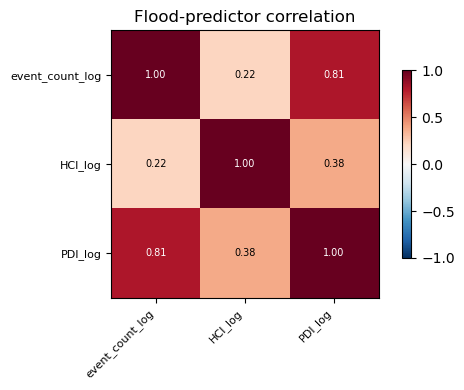

In [43]:
# correlation heatmap of flood predictors
cc = panel[FLOOD].corr()
fig, ax = plt.subplots(figsize=(1.2*len(FLOOD)+2, 1.0*len(FLOOD)+1))
im = ax.imshow(cc.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FLOOD))); ax.set_xticklabels(FLOOD, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(FLOOD))); ax.set_yticklabels(FLOOD, fontsize=8)
for i in range(len(FLOOD)):
    for j in range(len(FLOOD)):
        ax.text(j, i, f"{cc.values[i,j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(cc.values[i,j])>0.5 else "black")
plt.colorbar(im, shrink=0.7); ax.set_title("Flood-predictor correlation"); plt.tight_layout(); plt.show()

## STEP 3 — Estimator selection — CEM vs FE vs RE (Chow · LM · Hausman)

In [45]:
# ═════════════════════════════════════════════════════════════
# STEP 3 — Estimator selection — CEM vs FE vs RE
# ═════════════════════════════════════════════════════════════
Y = "grdp_growth_pct"
sub = pdat[[Y]+X].dropna()
cem = PooledOLS(sub[Y], sub[X].assign(const=1)).fit()
fe  = PanelOLS(sub[Y], sub[X], entity_effects=True, time_effects=True,
               drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
re  = RandomEffects(sub[Y], sub[X].assign(const=1)).fit()
print("ESTIMATORS")
print(f"  CEM (Pooled OLS): R2={cem.rsquared:.4f}")
print(f"  Fixed Effects   : within-R2={fe.rsquared_within:.4f}")
print(f"  Random Effects  : R2={re.rsquared:.4f}")

print(f"\n[Chow] F-test entity effects (CEM vs FE): F={fe.f_pooled.stat:.2f}, p={fe.f_pooled.pval:.4g}")
print("   -> " + ("entity effects significant -> FE over CEM" if fe.f_pooled.pval<0.05 else "CEM adequate"))

_u = pd.DataFrame({"u": cem.resids.values}, index=cem.resids.index)
_g = _u.groupby(level=0)["u"]; _T=_g.count(); _n=len(_u)
if _T.nunique()==1:
    LM=(_n/(2*(_T.iloc[0]-1)))*((_g.sum()**2).sum()/(_u["u"]**2).sum()-1)**2
    print(f"[LM]   Breusch-Pagan (CEM vs RE): LM={LM:.2f}, p={1-chi2.cdf(LM,1):.4g}")
    print("   -> " + ("individual effects present -> panel needed" if (1-chi2.cdf(LM,1))<0.05 else "no individual effects"))

common=[c for c in FLOOD if c in fe.params.index and c in re.params.index]
d=(fe.params[common]-re.params[common]).values
vd=(fe.cov.loc[common,common]-re.cov.loc[common,common]).values
h=float(d.T@np.linalg.pinv(vd)@d)
print(f"[Hausman] FE vs RE: chi2={h:.2f}, p={1-chi2.cdf(h,len(common)):.4g}")
flips=sum(1 for v in common if fe.params[v]*re.params[v]<0)
if h<0: print("   -> NEGATIVE (clustered-SE artifact); decide via coefficient gaps + theory")
print(f"   FE vs RE sign flips: {flips} -> "+("RE biased -> FE consistent" if flips else "similar"))
print("\nDECISION: Fixed Effects (Chow+LM reject pooled; FE/RE divergence + theory -> RE inconsistent).")

ESTIMATORS
  CEM (Pooled OLS): R2=0.0088
  Fixed Effects   : within-R2=0.0092
  Random Effects  : R2=0.0092

[Chow] F-test entity effects (CEM vs FE): F=20.08, p=0
   -> entity effects significant -> FE over CEM
[LM]   Breusch-Pagan (CEM vs RE): LM=222.71, p=0
   -> individual effects present -> panel needed
[Hausman] FE vs RE: chi2=-99.94, p=1
   -> NEGATIVE (clustered-SE artifact); decide via coefficient gaps + theory
   FE vs RE sign flips: 1 -> RE biased -> FE consistent

DECISION: Fixed Effects (Chow+LM reject pooled; FE/RE divergence + theory -> RE inconsistent).


## STEP 4 — Significance across 17 sectors — BH-FDR vs uncorrected

17 sectors = 17 simultaneous tests per flood dimension. Without correction ~1 in 20 is a false positive. We show **both** uncorrected and BH-FDR-corrected significance so the effect of multiple-testing control is explicit. BH-FDR is applied per dimension (each dimension = its own family).

In [47]:
# ═════════════════════════════════════════════════════════════
# STEP 4 — Significance across 17 sectors — BH-FDR vs uncorrected
# ═════════════════════════════════════════════════════════════
SECTORS = ["grdp_A_agriculture","grdp_B_mining","grdp_C_manufacturing","grdp_D_electricity",
           "grdp_E_water","grdp_F_construction","grdp_G_trade","grdp_H_transport",
           "grdp_I_accommodation","grdp_J_infocomm","grdp_K_finance","grdp_L_realestate",
           "grdp_MN_business","grdp_O_government","grdp_P_education","grdp_Q_health","grdp_RSTU_other"]
for s in SECTORS:
    if f"{s}_growth" not in panel.columns:
        g = panel.groupby("bps_kab_code")[s].pct_change()*100
        g = g.replace([np.inf,-np.inf],np.nan); lo,hi=g.quantile([.01,.99]); panel[f"{s}_growth"]=g.clip(lo,hi)
pdat = panel.set_index(["bps_kab_code","year"])

rows=[]
for s in SECTORS:
    sub=pdat[[f"{s}_growth"]+X].dropna()
    r=PanelOLS(sub[f"{s}_growth"],sub[X],entity_effects=True,time_effects=True,drop_absorbed=True).fit(cov_type="kernel")
    row={"sector":s.replace("grdp_","")}
    for f in FLOOD:
        row[f"b_{f}"]=r.params[f]; row[f"p_{f}"]=r.pvalues[f]
    rows.append(row)
res=pd.DataFrame(rows)
# BH per flood dimension
for f in FLOOD:
    res[f"pBH_{f}"]=multipletests(res[f"p_{f}"].values,method="fdr_bh")[1]
    res[f"sigRAW_{f}"]=res[f"p_{f}"]<0.05
    res[f"sigBH_{f}"]=res[f"pBH_{f}"]<0.05

print("Significant sectors — UNCORRECTED vs BH-FDR (per flood dimension):\n")
for f in FLOOD:
    raw=list(res.loc[res[f"sigRAW_{f}"],"sector"])
    bh =list(res.loc[res[f"sigBH_{f}"],"sector"])
    print(f"  {f}:")
    print(f"    uncorrected (p<0.05): {len(raw)} -> {raw if raw else 'none'}")
    print(f"    BH-FDR      (p<0.05): {len(bh)} -> {bh if bh else 'none'}")
    print(f"    dropped by correction: {sorted(set(raw)-set(bh)) or 'none'}\n")
print("  Interpretation: sectors that survive BH-FDR are the defensible claims;")
print("  those dropped were likely false positives from multiple testing.")

Significant sectors — UNCORRECTED vs BH-FDR (per flood dimension):

  event_count_log:
    uncorrected (p<0.05): 4 -> ['F_construction', 'G_trade', 'MN_business', 'Q_health']
    BH-FDR      (p<0.05): 2 -> ['G_trade', 'Q_health']
    dropped by correction: ['F_construction', 'MN_business']

  HCI_log:
    uncorrected (p<0.05): 5 -> ['I_accommodation', 'K_finance', 'MN_business', 'P_education', 'RSTU_other']
    BH-FDR      (p<0.05): 1 -> ['P_education']
    dropped by correction: ['I_accommodation', 'K_finance', 'MN_business', 'RSTU_other']

  PDI_log:
    uncorrected (p<0.05): 4 -> ['B_mining', 'C_manufacturing', 'J_infocomm', 'L_realestate']
    BH-FDR      (p<0.05): 2 -> ['B_mining', 'C_manufacturing']
    dropped by correction: ['J_infocomm', 'L_realestate']

  Interpretation: sectors that survive BH-FDR are the defensible claims;
  those dropped were likely false positives from multiple testing.


### Mundlak test (Correlated Random Effects)

The choice between fixed and random effects is assessed using the Mundlak
(1978) device, which augments a random-effects model with the within-regency
means of the time-varying regressors and tests their joint significance. A
significant result indicates the regency effect is correlated with the
regressors, so random effects are inconsistent and fixed effects are preferred.
This replaces the Hausman test, whose coefficient-covariance difference was not
positive-definite under clustered errors (a negative chi-square).

- **H0:** group-mean coefficients jointly zero → RE consistent
- **H1:** at least one non-zero → RE inconsistent → **FE preferred**

For the 17 sectoral models, the test is run separately per sector, since each
sector is an independent fixed-effects regression.

In [49]:
# ══════════════════════════════════════════════════════════════════════
# MUNDLAK TEST helper — reusable for TPT, poverty, and each sector
# ══════════════════════════════════════════════════════════════════════
from linearmodels.panel import RandomEffects
from scipy.stats import chi2

def mundlak_test(pdat, outcome, X, label=""):
    """Mundlak CRE test. Returns dict with Wald, p, and verdict.
    X = the exact regressors of the estimated model (Option B: lagged flood
    + contemporaneous controls)."""
    sub = pdat[[outcome] + X].dropna().copy()
    if len(sub) == 0:
        return {"label": label, "wald": np.nan, "p": np.nan, "verdict": "no data"}
    gm = sub.groupby(level=0)[X].transform("mean")
    gm.columns = [f"{c}_gm" for c in X]
    X_aug = pd.concat([sub[X], gm], axis=1).assign(const=1)
    try:
        re = RandomEffects(sub[outcome], X_aug).fit()
        gm_cols = [f"{c}_gm" for c in X]
        b = re.params[gm_cols].values
        V = re.cov.loc[gm_cols, gm_cols].values
        wald = float(b @ np.linalg.pinv(V) @ b)
        p = float(chi2.sf(wald, len(gm_cols)))
        if wald < 0:
            verdict = "NEGATIVE Wald (artefact) -> use Chow+LM+theory"
        elif p < 0.05:
            verdict = "FE preferred (reject RE)"
        else:
            verdict = "RE may be adequate (re-check)"
        return {"label": label, "wald": wald, "p": p, "verdict": verdict}
    except Exception as e:
        return {"label": label, "wald": np.nan, "p": np.nan,
                "verdict": f"failed: {str(e)[:40]}"}

In [50]:
# ── Mundlak for each of the 17 sectors ──
print("MUNDLAK TEST — 17 sectors (Option B)")
print("=" * 60)
print(f"  {'sector':<18}{'Wald':>10}{'p':>12}  verdict")
print("  " + "-" * 58)
mundlak_rows = []
for s in SECTORS:
    r = mundlak_test(pdat, f"{s}_growth", X, label=s.replace("grdp_", ""))
    mundlak_rows.append(r)
    print(f"  {r['label']:<18}{r['wald']:>10.3f}{r['p']:>12.4g}  {r['verdict']}")

mundlak_sectors = pd.DataFrame(mundlak_rows)
n_fe = (mundlak_sectors["p"] < 0.05).sum()
print("  " + "-" * 58)
print(f"  FE preferred (p<0.05): {n_fe}/{len(SECTORS)} sectors")
# NOTE: Report the count of sectors where Mundlak prefers FE. If the large
# majority reject RE, state that FE is used uniformly across sectors for
# consistency and comparability, with the Mundlak result reported in aggregate
# (e.g. "FE preferred in X of 17 sectors"). Running RE for a handful of sectors
# and FE for the rest would break cross-sector comparability.

MUNDLAK TEST — 17 sectors (Option B)
  sector                  Wald           p  verdict
  ----------------------------------------------------------
  A_agriculture         29.791   1.621e-05  FE preferred (reject RE)
  B_mining              14.597     0.01223  FE preferred (reject RE)
  C_manufacturing       30.758   1.046e-05  FE preferred (reject RE)
  D_electricity         20.290    0.001102  FE preferred (reject RE)
  E_water              216.270   9.353e-45  FE preferred (reject RE)
  F_construction       149.316   1.867e-30  FE preferred (reject RE)
  G_trade               19.763    0.001384  FE preferred (reject RE)
  H_transport           76.855   3.813e-15  FE preferred (reject RE)
  I_accommodation       58.764   2.188e-11  FE preferred (reject RE)
  J_infocomm           424.709   1.398e-89  FE preferred (reject RE)
  K_finance             30.573   1.137e-05  FE preferred (reject RE)
  L_realestate          68.611   1.993e-13  FE preferred (reject RE)
  MN_business         

In [51]:
# ══════════════════════════════════════════════════════════════════════
# MUNDLAK / CRE TEST — full model vs flood-only diagnostic, per sector
# (uses the SAME test logic as 9a_growth_3dim.ipynb, not the simplified
# "Option B" helper -- output kept compact given 17 sectors x 2 tests)
# ══════════════════════════════════════════════════════════════════════
from linearmodels.panel import RandomEffects
from scipy.stats import chi2
import numpy as np


def mundlak_test(_pdat, Xvars, Y):
    """Mundlak/CRE joint test that regency means are zero (H0: RE consistent).
    Identical logic to 9a_growth_3dim.ipynb's mundlak_test, generalised to
    take an explicit outcome column (Y) so it can be reused per sector."""
    sub = _pdat[[Y] + Xvars].dropna()
    if len(sub) == 0:
        return {"chi2": np.nan, "dof": len(Xvars), "p": np.nan, "correlated": []}
    grp = sub.groupby(level=0)
    sub_m = sub.copy()
    mean_cols = []
    for c in Xvars:
        sub_m[c + "_mean"] = grp[c].transform("mean")
        mean_cols.append(c + "_mean")
    re_m = RandomEffects(sub_m[Y], sub_m[Xvars + mean_cols].assign(const=1)).fit()
    mp   = re_m.params[mean_cols].values
    cov  = re_m.cov.loc[mean_cols, mean_cols].values
    stat = float(mp @ np.linalg.inv(cov) @ mp)
    dof  = len(mean_cols)
    p    = 1 - chi2.cdf(stat, dof)
    sig  = [c.replace("_mean", "") for c in mean_cols if re_m.pvalues[c] < 0.05]
    return {"chi2": stat, "dof": dof, "p": p, "correlated": sig}


# ── Mundlak for each of the 17 sectors: full model + flood-only ──
print("MUNDLAK TEST — 17 sectors (full model vs flood-only)")
print("=" * 78)
print(f"  {'Sector':<18}{'Full: chi2':>12}{'Full: p':>12}  {'Flood: chi2':>12}{'Flood: p':>12}  Verdict")
print("  " + "-" * 76)

mundlak_rows = []
for s in SECTORS:
    y = f"{s}_growth"
    res_full  = mundlak_test(pdat, FLOOD + CONTROLS, y)
    res_flood = mundlak_test(pdat, FLOOD, y)
    verdict = "FE preferred" if (not np.isnan(res_full["p"]) and res_full["p"] < 0.05) else "RE may be adequate"
    label = s.replace("grdp_", "")
    print(f"  {label:<18}{res_full['chi2']:>12.3f}{res_full['p']:>12.4g}  "
          f"{res_flood['chi2']:>12.3f}{res_flood['p']:>12.4g}  {verdict}")
    mundlak_rows.append({
        "sector": label,
        "full_chi2": res_full["chi2"], "full_p": res_full["p"],
        "flood_chi2": res_flood["chi2"], "flood_p": res_flood["p"],
        "verdict": verdict,
    })

mundlak_sectors = pd.DataFrame(mundlak_rows)
n_fe = (mundlak_sectors["full_p"] < 0.05).sum()
print("  " + "-" * 76)
print(f"  FE preferred (full model, p<0.05): {n_fe}/{len(SECTORS)} sectors")

# NOTE: Report the count of sectors where Mundlak prefers FE for the full
# model. If the large majority reject RE, state that FE is used uniformly
# across sectors for consistency and comparability, with the Mundlak result
# reported in aggregate (e.g. "FE preferred in X of 17 sectors"). Running RE
# for a handful of sectors and FE for the rest would break cross-sector
# comparability. The flood-only column additionally shows, per sector,
# whether RE-inconsistency is driven by the flood block itself or only by
# the controls -- mirroring the diagnostic reported for growth.

MUNDLAK TEST — 17 sectors (full model vs flood-only)
  Sector              Full: chi2     Full: p   Flood: chi2    Flood: p  Verdict
  ----------------------------------------------------------------------------
  A_agriculture           29.791   1.621e-05        20.223   0.0001526  FE preferred
  B_mining                14.597     0.01223         1.850      0.6042  FE preferred
  C_manufacturing         30.758   1.046e-05        11.487    0.009364  FE preferred
  D_electricity           20.290    0.001102        22.029   6.433e-05  FE preferred
  E_water                216.270           0        46.480   4.484e-10  FE preferred
  F_construction         149.316           0        22.095   6.233e-05  FE preferred
  G_trade                 19.763    0.001384         8.442     0.03771  FE preferred
  H_transport             76.855   3.775e-15        16.196    0.001034  FE preferred
  I_accommodation         58.764   2.188e-11         4.932      0.1769  FE preferred
  J_infocomm           

## STEP 5 — Clustered vs Driscoll–Kraay — per-sector comparison + per-sector CD test

SE choice can matter differently per sector. We report both SEs and a per-sector Pesaran CD test, so sectors with strong spatial dependence (where DK is preferred) are visible.

In [53]:
# ═════════════════════════════════════════════════════════════
# STEP 5 — Clustered vs Driscoll–Kraay — per-sector CD test
# ═════════════════════════════════════════════════════════════
def cd(resid):
    wide=resid.unstack(level=0); cmat=wide.corr().values
    n=cmat.shape[0]; T=wide.shape[0]; off=cmat[np.triu_indices(n,1)]; off=off[~np.isnan(off)]
    return np.sqrt(2*T/len(off))*off.sum()

rows=[]
for s in SECTORS:
    sub=pdat[[f"{s}_growth"]+X].dropna()
    m=PanelOLS(sub[f"{s}_growth"],sub[X],entity_effects=True,time_effects=True,drop_absorbed=True)
    rc=m.fit(cov_type="clustered",cluster_entity=True); rd=m.fit(cov_type="kernel")
    # Two adequacy tests:
    #  (a) overall model F-test (all 5 predictors = 0) — reported for context
    #  (b) flood-block Wald test (event+HCI+PDI = 0) — the CORRECT joint test for
    #      "does the flood block explain sector growth?"; used as the model gate.
    _wald = rd.wald_test(formula=" = 0, ".join(FLOOD) + " = 0")
    rows.append({"sector":s.replace("grdp_",""),"CD":cd(rd.resids),
                 "overall_F_pval":float(rd.f_statistic.pval),          # all predictors (context only)
                 "flood_block_pval":float(_wald.pval),                 # flood block joint test (the gate)
                 "model_significant":bool(_wald.pval<0.05),            # gate on flood block, NOT overall F
                 **{f"pcl_{f}":rc.pvalues[f] for f in FLOOD},
                 **{f"pdk_{f}":rd.pvalues[f] for f in FLOOD}})
se=pd.DataFrame(rows)
print("Per-sector CD test (spatial dependence on residuals):\n")
for _,r in se.sort_values("CD",ascending=False).iterrows():
    tag="STRONG -> DK preferred" if abs(r["CD"])>1.96 else "weak -> clustered ok"
    print(f"  {r['sector']:<16} CD={r['CD']:>7.2f}  {tag}")
print("\n  Sectors with strong spatial dependence need DK; others are SE-insensitive.")

Per-sector CD test (spatial dependence on residuals):

  H_transport      CD=  59.60  STRONG -> DK preferred
  K_finance        CD=  11.34  STRONG -> DK preferred
  C_manufacturing  CD=  11.05  STRONG -> DK preferred
  J_infocomm       CD=   7.14  STRONG -> DK preferred
  MN_business      CD=   6.37  STRONG -> DK preferred
  I_accommodation  CD=   5.97  STRONG -> DK preferred
  RSTU_other       CD=   4.22  STRONG -> DK preferred
  Q_health         CD=   2.55  STRONG -> DK preferred
  F_construction   CD=   1.39  weak -> clustered ok
  A_agriculture    CD=   0.32  weak -> clustered ok
  G_trade          CD=  -0.11  weak -> clustered ok
  D_electricity    CD=  -0.24  weak -> clustered ok
  L_realestate     CD=  -0.32  weak -> clustered ok
  B_mining         CD=  -0.50  weak -> clustered ok
  O_government     CD=  -1.20  weak -> clustered ok
  E_water          CD=  -1.84  weak -> clustered ok
  P_education      CD=  -2.06  STRONG -> DK preferred

  Sectors with strong spatial dependence n

## STEP 6 — Model evaluation & robustness

Residual diagnostics (heteroskedasticity, normality, autocorrelation) with plots, coefficient stability across the control ladder, and robustness to SE & sample. Diagnostics use the headline outcome; for sector files the same code applies per chosen sector.

RESIDUAL DIAGNOSTICS
  Jarque-Bera (normality)        stat=31665.1  p=0  -> non-normal
  Breusch-Pagan (heterosked.)    LM=51.1  p=8.353e-10  -> heteroskedastic
  Durbin-Watson (autocorr.)      1.819  (2 = none)
  Skewness=0.455  Excess kurtosis=12.125

  -> heavy tails / heteroskedasticity expected in regency panels; handled by
     robust SEs (clustered / Driscoll-Kraay) + large-n CLT, NOT by changing the model.


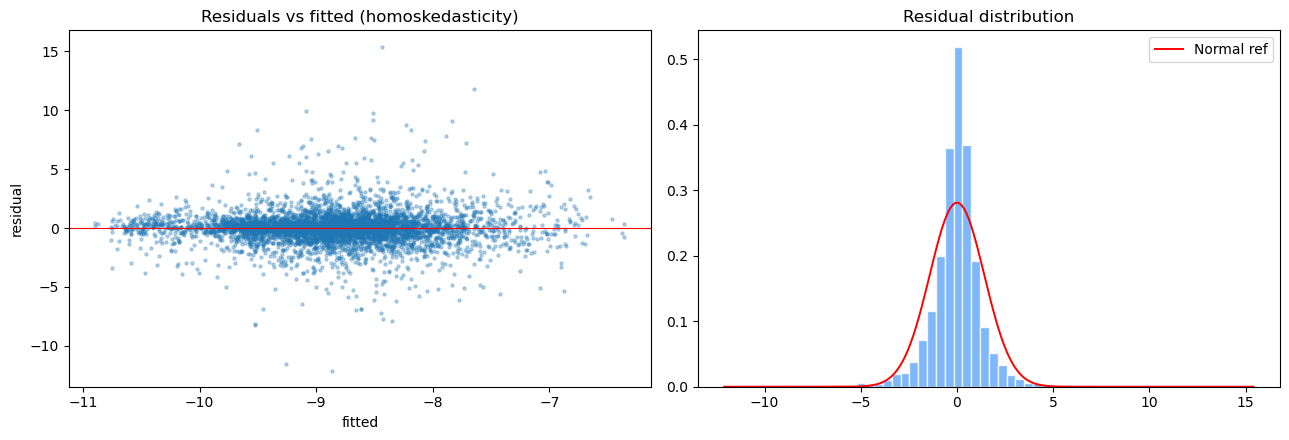

In [55]:
# ═════════════════════════════════════════════════════════════
# STEP 6 — Model evaluation & robustness
# ═════════════════════════════════════════════════════════════
Y_EVAL = "grdp_growth_pct"
sub = pdat[[Y_EVAL]+X].dropna()
fe = PanelOLS(sub[Y_EVAL], sub[X], entity_effects=True, time_effects=True,
              drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
resid = fe.resids.values.ravel(); fitted = fe.fitted_values.values.ravel()

# diagnostic statistics
jb_stat, jb_p = jarque_bera(resid)
from scipy import stats as _st
skew=_st.skew(resid); exkurt=_st.kurtosis(resid)
_ex = sub[X].loc[fe.resids.index]
bp_lm, bp_p, _, _ = het_breuschpagan(resid, np.column_stack([np.ones(len(_ex)), _ex.values]))
dw = durbin_watson(resid)
print("RESIDUAL DIAGNOSTICS")
print(f"  Jarque-Bera (normality)        stat={jb_stat:.1f}  p={jb_p:.4g}  -> {'non-normal' if jb_p<0.05 else 'normal'}")
print(f"  Breusch-Pagan (heterosked.)    LM={bp_lm:.1f}  p={bp_p:.4g}  -> {'heteroskedastic' if bp_p<0.05 else 'homoskedastic'}")
print(f"  Durbin-Watson (autocorr.)      {dw:.3f}  (2 = none)")
print(f"  Skewness={skew:.3f}  Excess kurtosis={exkurt:.3f}")
print("\n  -> heavy tails / heteroskedasticity expected in regency panels; handled by")
print("     robust SEs (clustered / Driscoll-Kraay) + large-n CLT, NOT by changing the model.")

fig, ax = plt.subplots(1, 2, figsize=(13,4.5))
ax[0].scatter(fitted, resid, s=5, alpha=0.3); ax[0].axhline(0, color="red", lw=.8)
ax[0].set_title("Residuals vs fitted (homoskedasticity)"); ax[0].set_xlabel("fitted"); ax[0].set_ylabel("residual")
ax[1].hist(resid, bins=60, density=True, color="#60a5fa", edgecolor="white", alpha=.8)
_xx=np.linspace(resid.min(),resid.max(),200); ax[1].plot(_xx,_st.norm.pdf(_xx,resid.mean(),resid.std()),"r-",lw=1.4,label="Normal ref")
ax[1].set_title("Residual distribution"); ax[1].legend(); plt.tight_layout(); plt.show()

In [56]:
# Coefficient stability across control ladder (key flood predictor)
KEY = FLOOD[-1] if "sector"=="growth" else FLOOD[-1]
KEY = "fasum_damaged_log" if "fasum_damaged_log" in FLOOD else FLOOD[-1]
Y_EVAL = "grdp_growth_pct"
ladder = [("flood only", FLOOD), ("+ log_population", FLOOD+["log_population"]),
          ("+ rls_years (FULL)", FLOOD+CONTROLS)]
print(f"Coefficient stability of {KEY} on {Y_EVAL} (Driscoll-Kraay):\n")
print(f"  specification               beta        p")
bs=[]
for nm,xv in ladder:
    sub=pdat[[Y_EVAL]+xv].dropna()
    r=PanelOLS(sub[Y_EVAL],sub[xv],entity_effects=True,time_effects=True,drop_absorbed=True).fit(cov_type="kernel")
    bs.append(r.params[KEY]); print(f"  {nm:<22}{r.params[KEY]:>10.4f}{r.pvalues[KEY]:>9.4f}")
print(f"  range={max(bs)-min(bs):.4f} -> {'STABLE (control-insensitive)' if max(bs)-min(bs)<abs(np.mean(bs))*0.3 else 'sensitive'}")

# robustness to SE & sample
print(f"\nRobustness of {KEY} to SE & sample:")
print(f"  variant                         beta        p")
sub=pdat[[Y_EVAL]+X].dropna()
mm=PanelOLS(sub[Y_EVAL],sub[X],entity_effects=True,time_effects=True,drop_absorbed=True)
for lab,cov in [("clustered",dict(cov_type="clustered",cluster_entity=True)),("Driscoll-Kraay",dict(cov_type="kernel")),("robust",dict(cov_type="robust"))]:
    r=mm.fit(**cov); print(f"  {lab:<26}{r.params[KEY]:>10.4f}{r.pvalues[KEY]:>9.4f}")
for lo,hi in [(2016,2020),(2021,2025)]:
    s2=panel[(panel.year>=lo)&(panel.year<=hi)].set_index(["bps_kab_code","year"])
    s2=s2[[Y_EVAL]+X].dropna()
    r=PanelOLS(s2[Y_EVAL],s2[X],entity_effects=True,time_effects=True,drop_absorbed=True).fit(cov_type="kernel")
    print(f"  {f'subsample {lo}-{hi}':<26}{r.params[KEY]:>10.4f}{r.pvalues[KEY]:>9.4f}")

Coefficient stability of PDI_log on grdp_growth_pct (Driscoll-Kraay):

  specification               beta        p
  flood only               -0.0216   0.0148
  + log_population         -0.0217   0.0153
  + rls_years (FULL)       -0.0216   0.0143
  range=0.0002 -> STABLE (control-insensitive)

Robustness of PDI_log to SE & sample:
  variant                         beta        p
  clustered                    -0.0216   0.0192
  Driscoll-Kraay               -0.0216   0.0143
  robust                       -0.0216   0.0071
  subsample 2016-2020          -0.0045   0.5834
  subsample 2021-2025          -0.0295   0.0278


## STEP 7 — Model fit summary (AIC / BIC / R² / F / RMSE)

Reference metrics for this specification. **Important:** AIC and BIC are *relative* measures — a single value is not interpretable on its own; it is only meaningful when **compared across files** on the same outcome (e.g. this file's AIC vs the 7-variable file's AIC for growth, or 3-dim vs 7-var for sectors). Record these values and compare them in `9b_model_comparison_3dim_vs_7comp.ipynb`.

- **within-R² / adj. within-R²** — variation explained within regencies (adjusted penalises extra parameters)
- **AIC / BIC** — fit penalised for complexity; lower = better; BIC penalises parameters more strongly
- **log-likelihood** — model fit (higher = better)
- **F-statistic** — joint significance of all regressors
- **RMSE** — residual standard deviation (typical prediction error)

In [62]:
# ═════════════════════════════════════════════════════════════
# STEP 7 — Model fit summary per sector
# ═════════════════════════════════════════════════════════════
def model_fit_summary(res, n_params):
    n = res.nobs
    return {
        "within_R2":     res.rsquared_within,
        "adj_within_R2": 1 - (1 - res.rsquared_within) * (n - 1) / (n - n_params - 1),
        "AIC":           2 * n_params - 2 * res.loglik,
        "BIC":           n_params * np.log(n) - 2 * res.loglik,
        "logLik":        res.loglik,
        "RMSE":          res.resids.std(),
        "n":             int(n),
    }

# per-sector fit metrics, then aggregate (17 sectors -> summary stats)
fit_rows = []
for s in SECTORS:
    sub = pdat[[f"{s}_growth"] + X].dropna()
    r = PanelOLS(sub[f"{s}_growth"], sub[X], entity_effects=True, time_effects=True,
                 drop_absorbed=True).fit(cov_type="kernel")
    m = model_fit_summary(r, len(X)); m["sector"] = s.replace("grdp_", "")
    fit_rows.append(m)
fitdf = pd.DataFrame(fit_rows).set_index("sector")

print(f"MODEL FIT PER SECTOR ({len(FLOOD)}-variable flood spec) — AIC/BIC/within-R2:\n")
print(fitdf[["within_R2", "adj_within_R2", "AIC", "BIC", "RMSE"]].round(3).to_string())
print(f"""
  AGGREGATE across 17 sectors:
    within-R2 : mean={fitdf['within_R2'].mean():.4f}  range=[{fitdf['within_R2'].min():.4f}, {fitdf['within_R2'].max():.4f}]
    AIC       : mean={fitdf['AIC'].mean():.0f}  range=[{fitdf['AIC'].min():.0f}, {fitdf['AIC'].max():.0f}]
    BIC       : mean={fitdf['BIC'].mean():.0f}  range=[{fitdf['BIC'].min():.0f}, {fitdf['BIC'].max():.0f}]

  To compare 3-dim vs 7-var at sector level: compare the SAME sector's AIC/BIC
  across the two files (lower = better). Aggregate mean AIC/BIC gives the overall
  picture; BIC is the parsimony-strict criterion. Single values are reference only.""")

MODEL FIT PER SECTOR (3-variable flood spec) — AIC/BIC/within-R2:

                 within_R2  adj_within_R2        AIC        BIC   RMSE
sector                                                                
A_agriculture       -0.003         -0.004  19500.267  19532.464  1.989
B_mining            -0.005         -0.006  26245.497  26277.440  4.784
C_manufacturing      0.002          0.001  24579.489  24611.682  3.452
D_electricity       -0.003         -0.004  25690.049  25722.186  4.016
E_water              0.009          0.008  22086.856  22118.906  2.825
F_construction       0.018          0.016  24312.722  24344.919  3.347
G_trade             -0.004         -0.005  20214.548  20246.745  2.149
H_transport         -0.005         -0.006  29248.782  29280.979  5.706
I_accommodation     -0.010         -0.011  25445.098  25477.295  3.782
J_infocomm           0.038          0.036  21472.184  21504.371  2.473
K_finance            0.001          0.000  24342.111  24374.259  3.445
L_realesta

## STEP 8 — Save sector results → fit_9b.json (for the dashboard bar chart)

Exports per-sector × per-dimension coefficients with both SE families, so the
dashboard reads the EXACT 9b results (single source of truth — no recompute).

For each sector × {event, HCI, PDI}:
- `beta`, `pBH_clustered`, `pBH_DK` (both BH-FDR corrected)
- `flag`: `**` robust (sig both SE) · `~cl` clustered-only · `~dk` DK-only · `` n.s.
- `CD`: per-sector Pesaran cross-sectional dependence (context)

In [78]:
# ═════════════════════════════════════════════════════════════
# STEP 8 — Save per-sector results
# ═════════════════════════════════════════════════════════════
# ── SAVE sector results to fit_9b.json (dashboard bar chart source) ──
import json
from statsmodels.stats.multitest import multipletests

# `res` (cell with clustered + BH) and `se` (cell with CD + pcl/pdk) exist above.
# Apply BH-FDR to the DK p-values too (per dimension), to mirror the clustered BH.
_se = se.copy()
for f in FLOOD:
    _se[f"pdkBH_{f}"] = multipletests(_se[f"pdk_{f}"].values, method="fdr_bh")[1]
    _se[f"pclBH_{f}"] = multipletests(_se[f"pcl_{f}"].values, method="fdr_bh")[1]

# beta per sector×dim — recover from `res` if present, else from a fresh fit
def _beta_lookup(sector, f):
    r = res[res["sector"] == sector]
    col = f"b_{f}" if f"b_{f}" in res.columns else None
    if col is not None and len(r):
        return float(r[col].iloc[0])
    return None

_dim_name = {FLOOD[0]: "event", FLOOD[1]: "HCI", FLOOD[2]: "PDI"}
sectors_out = {}
for _, r in _se.iterrows():
    sec = r["sector"]
    dims = {}
    for f in FLOOD:
        pcl = float(r[f"pclBH_{f}"]); pdk = float(r[f"pdkBH_{f}"])
        sig_cl, sig_dk = pcl < 0.05, pdk < 0.05
        flag = ("**" if sig_cl and sig_dk else
                "~cl" if sig_cl else
                "~dk" if sig_dk else "")
        dims[_dim_name[f]] = {
            "beta": _beta_lookup(sec, f),
            "pBH_clustered": pcl, "pBH_DK": pdk, "flag": flag,
            "sig_any": bool(sig_cl or sig_dk),
        }
    sectors_out[sec] = {"CD": float(r["CD"]),
                        "overall_F_pval": float(r["overall_F_pval"]),
                        "flood_block_pval": float(r["flood_block_pval"]),
                        "model_significant": bool(r["model_significant"]),
                        "dims": dims}

payload = {
    "file": "9b", "spec": "3-dimension (event, HCI, PDI)", "outcome": "sector growth",
    "n_sectors": len(sectors_out),
    "flag_legend": {"**": "robust (sig both SE)", "~cl": "clustered-only",
                    "~dk": "DK-only", "": "n.s."},
    "model_note": "model_significant = flood block jointly significant via Wald test (event+HCI+PDI=0, p<0.05); overall_F_pval (all predictors) reported for context only",
    "sectors": sectors_out,
}
with open("../data/processed/fit_9b.json", "w") as _f:
    json.dump(payload, _f, indent=2)

# summary
_robust = [(s, d) for s, v in sectors_out.items() for d, x in v["dims"].items() if x["flag"] == "**"]
_sugg   = [(s, d) for s, v in sectors_out.items() for d, x in v["dims"].items() if x["flag"].startswith("~")]
print(f"✓ saved fit_9b.json — {len(sectors_out)} sectors")
print(f"  ROBUST (**):     {len(_robust)} -> {_robust}")
print(f"  SUGGESTIVE (~):  {len(_sugg)}")
print(f"  (the rest are n.s. — reported in the dashboard note)")

✓ saved fit_9b.json — 17 sectors
  ROBUST (**):     3 -> [('G_trade', 'event'), ('P_education', 'HCI'), ('Q_health', 'event')]
  SUGGESTIVE (~):  8
  (the rest are n.s. — reported in the dashboard note)


## STEP 9 — Master sector table & grouped summary (for the thesis write-up)

In [68]:
# ═════════════════════════════════════════════════════════════
# STEP 9 — Master sector table & grouped summary
# ═════════════════════════════════════════════════════════════
# ── Master sector table + grouped summary (printed for the thesis) ──
# Uses `sectors_out` + `_se` built in the save cell above.
print("MASTER SECTOR TABLE — beta | pBH(clustered) | pBH(Driscoll-Kraay) | flag")
print("  flags: ** = sig BOTH SEs (robust)   ~cl = clustered only   ~dk = DK only\n")
_hdr = f"{'sector':<15}|  {'event (b / pCL / pDK / f)':<26} |  {'HCI (b / pCL / pDK / f)':<26} |  {'PDI (b / pCL / pDK / f)':<26}"
print(_hdr); print("-" * len(_hdr))
for sec, v in sectors_out.items():
    cells = []
    for dim in ["event", "HCI", "PDI"]:
        d = v["dims"][dim]
        b = d["beta"]; pcl = d["pBH_clustered"]; pdk = d["pBH_DK"]; fl = d["flag"]
        cells.append(f"{b:+.3f}  {pcl:.3f}  {pdk:.3f}  {fl:<4}")
    print(f"{sec:<15}| {cells[0]:<27}| {cells[1]:<27}| {cells[2]:<27}")

# grouped summary by SE agreement
print("\n" + "=" * 74)
print("SUMMARY — significant sector x dimension effects, grouped by SE agreement")
print("(BH-FDR corrected; model_significant = flood block jointly sig via F-test)\n")

def _collect(flag_test):
    out = []
    for sec, v in sectors_out.items():
        for dim, d in v["dims"].items():
            if flag_test(d["flag"]):
                out.append((sec, dim, d["beta"], d["pBH_clustered"], d["pBH_DK"],
                            v.get("model_significant", True)))
    return out

_groups = [
    ("1. ROBUST  — significant under BOTH clustered AND Driscoll-Kraay:",
     lambda f: f == "**"),
    ("2. CLUSTERED SE ONLY  — significant under clustered, NOT under DK:",
     lambda f: f == "~cl"),
    ("3. DRISCOLL-KRAAY SE ONLY  — significant under DK, NOT under clustered:",
     lambda f: f == "~dk"),
]
for title, test in _groups:
    print(title)
    for sec, dim, b, pcl, pdk, mok in _collect(test):
        gate = "" if mok else "   [flood-block Wald n.s. -> would be excluded]"
        print(f"    {sec:<16} [{dim:<5}] beta={b:+.4f}  pBH_cl={pcl:.4f}  pBH_dk={pdk:.4f}{gate}")
    print()


# ── Model-adequacy table: two joint F-tests per sector ──────────────
print("\n" + "=" * 74)
print("MODEL ADEQUACY — joint tests per sector")
print("  overall-F   : H0 all predictors (flood + controls) = 0  (context only)")
print("  flood-Wald  : H0 flood block (event=HCI=PDI) = 0  (THE gate, p<0.05)")
print("  gate        : ✓ = flood block jointly significant -> effects shown\n")
print(f"  {'sector':<16}{'overall-F p':>13}{'flood-Wald p':>14}{'  gate':<8}")
print("  " + "-" * 52)
for sec, v in sectors_out.items():
    ofp = v.get("overall_F_pval", float("nan"))
    fwp = v.get("flood_block_pval", float("nan"))
    gate = "✓ sig" if v.get("model_significant") else "✗ n.s."
    print(f"  {sec:<16}{ofp:>13.4f}{fwp:>14.4f}  {gate:<8}")
print("  " + "-" * 52)
_n_gate = sum(v.get("model_significant", False) for v in sectors_out.values())
print(f"  flood block jointly significant: {_n_gate}/{len(sectors_out)} sectors")
print("""
  NOTE: overall-F and flood-Wald can DISAGREE. e.g. RSTU_other & B_mining have
  overall-F n.s. (controls add little) but flood-Wald SIGNIFICANT. Gating on the
  flood-block Wald (not overall-F) is correct: it isolates the flood contribution,
  which is exactly what the reported effects claim. No significant effect is
  dropped — all come from sectors whose flood block is jointly significant.""")


MASTER SECTOR TABLE — beta | pBH(clustered) | pBH(Driscoll-Kraay) | flag
  flags: ** = sig BOTH SEs (robust)   ~cl = clustered only   ~dk = DK only

sector         |  event (b / pCL / pDK / f)  |  HCI (b / pCL / pDK / f)    |  PDI (b / pCL / pDK / f)   
--------------------------------------------------------------------------------------------------------
A_agriculture  | +0.081  0.448  0.627       | -0.049  0.441  0.243       | -0.014  0.494  0.589       
B_mining       | +0.215  0.431  0.454       | +0.006  0.940  0.916       | -0.042  0.363  0.029  ~dk  
C_manufacturing| +0.155  0.424  0.486       | -0.018  0.940  0.799       | -0.071  0.098  0.006  ~dk  
D_electricity  | -0.160  0.490  0.601       | -0.008  0.940  0.916       | -0.018  0.725  0.612       
E_water        | +0.186  0.350  0.601       | -0.016  0.940  0.916       | -0.028  0.468  0.686       
F_construction | +0.397  0.049  0.064  ~cl  | -0.183  0.036  0.243  ~cl  | -0.007  0.985  0.984       
G_trade        | +0.297

## STEP 10 — Sector effects shown in the dashboard: all 11 significant effects

The BH-FDR–corrected results identify **11 significant sector × dimension effects** out of the 51 tested (17 sectors × 3 flood dimensions): **3 robust** (significant under both clustered and Driscoll–Kraay SE) and **8 suggestive** (significant under one SE type only).

**Model-adequacy check (two F-tests).** For each sector we report two joint tests:

1. **Overall model F-test** — null: all predictors (the 3 flood dimensions *and* the 2 controls) equal zero. This is the default `f_statistic` from the panel estimator. It is reported **for context only**, because it mixes the flood block with the controls.
2. **Flood-block Wald test** — null: the three flood coefficients jointly equal zero (`event = HCI = PDI = 0`). This is the **correct** test for the question "does the flood block explain sector growth?", and it is the one used as the model-adequacy gate.

**Result.** All 11 significant effects come from sectors whose **flood block is jointly significant** (Wald p < 0.05), so **none are excluded** — the dashboard shows all 11.

Note that the two tests can disagree. For **RSTU_other** and **B_mining**, the *overall* F-test is not significant (p ≈ 0.068 and 0.519) because the controls add little, yet the *flood-block* Wald test **is** significant (p ≈ 0.044 and 0.031). Gating on the flood-block test (not the overall F) is the methodologically correct choice: it isolates the flood contribution, which is exactly what these effects claim. Had we (incorrectly) gated on the overall F-test, we would have dropped two genuinely flood-significant effects.

**Transparency.** The full 17 × 3 master table, both F-tests per sector, and the evidence grade (robust vs suggestive) are all reported. The dashboard shows the 11 significant effects with colour-coded evidence strength, and notes that the majority (40 of 51, 78%) are not significant. Thesis and dashboard remain fully consistent.